# Fermions

This notebook shows how to define fermionic Hamiltonians with `jVMC_exp`, using the Fermi-Hubbard model as an example. The Hamiltonian is checked against [openfermion](https://quantumai.google/openfermion) (`pip install openfermion`), and its ground state is then found with a variational optimization.

In [10]:
import jVMC_exp
from jVMC_exp.operator.discrete import Number, Creation, Annihilation
from jVMC_exp.vqs import NQS

import jax.numpy as jnp
import flax.linen as nn
import numpy as np
import matplotlib.pyplot as plt

from openfermion.ops import FermionOperator as fop
from openfermion.linalg import get_sparse_operator

## Fermionic operators

Fermionic operators satisfy the anticommutation relations
$$
\lbrace \hat{c}^\dagger_{i\sigma}, \hat{c}_{j\sigma'}\rbrace  = \delta_{ij}\delta_{\sigma\sigma'} \; , \qquad \lbrace \hat{c}_{i\sigma}, \hat{c}_{j\sigma'}\rbrace = 0 \; ,
$$
where $i, j$ are sites and $\sigma, \sigma' \in \{\uparrow, \downarrow\}$ spins. They are created with `Creation(i, spin)`, `Annihilation(i, spin)` and `Number(i, spin)`, with `spin="up"` or `"down"`. Each site then has local dimension 4, with the local states

| local state | 0 | 1 | 2 | 3 |
|---|---|---|---|---|
| occupation | $\vert 0\rangle$ | $\vert\uparrow\rangle$ | $\vert\downarrow\rangle$ | $\vert\uparrow\downarrow\rangle$ |

so a configuration of $L$ sites is an array of shape `(L,)` with entries $0, \dots, 3$.

The anticommutation is realized by the Jordan-Wigner sign. The modes are ordered as $(0,\uparrow), (0,\downarrow), (1,\uparrow), (1,\downarrow), \dots$, and an operator acting on a mode picks up a factor $(-1)^{\Omega}$, where $\Omega$ counts the occupied modes that come **after** it in this order:
$$
\Omega_{i\uparrow} = n_{i\downarrow} + \sum_{j > i} \left(n_{j\uparrow} + n_{j\downarrow}\right) \; , \qquad
\Omega_{i\downarrow} = \sum_{j > i} \left(n_{j\uparrow} + n_{j\downarrow}\right) \; .
$$
For example, on a single site,
$$
\hat{c}^\dagger_{\uparrow}\vert \downarrow \rangle = -\vert \uparrow\downarrow\rangle \; , \qquad \hat{c}^\dagger_{\downarrow}\vert \uparrow \rangle = +\vert \uparrow\downarrow\rangle \; .
$$
Without the `spin` argument, the same operators describe spinless fermions, with local dimension 2 and $\Omega_i = \sum_{j>i} n_j$.

As an example, we construct the repulsive Hubbard model on an open chain,
$$
H = U \sum^{L}_{i=1} \hat{n}_{i\uparrow}\hat{n}_{i\downarrow} + \mu \sum^{L}_{i=1} \sum_{\sigma} \hat{n}_{i\sigma} + t \sum^{L-1}_{i=1} \sum_{\sigma} \left( \hat{c}^\dagger_{i\sigma} \hat{c}_{i+1\,\sigma} + \mathrm{h.c.} \right) \;.
$$

In [11]:
t = -1.0    # hopping
mu = -2.0   # chemical potential
U = 4.0     # interaction
L = 4       # number of sites

hamiltonian = 0
for i in range(L):
    # interaction
    hamiltonian += U * Number(i, "up") * Number(i, "down")
    # chemical potential
    hamiltonian += mu * (Number(i, "up") + Number(i, "down"))

    if i == L - 1:
        continue

    # hopping
    for spin in ("up", "down"):
        hamiltonian += t * (Creation(i, spin) * Annihilation(i + 1, spin) + Creation(i + 1, spin) * Annihilation(i, spin))

## Comparison with openfermion

To check the Hamiltonian, we build the same model with openfermion. Openfermion only has spinless modes, so we label the mode $(i, \sigma)$ by the index $2i$ for $\sigma=\uparrow$ and $2i+1$ for $\sigma=\downarrow$, which is the ordering used by `jVMC_exp`. Openfermion puts the Jordan-Wigner string on the modes *before* the operator instead of after it. For Hamiltonians where every term has an even number of fermionic operators, as is the case for any physical Hamiltonian, the two conventions give the same matrix, so the results can be compared directly.

To transfer wave functions from openfermion to `jVMC_exp`, we use `Target`, a simple custom network (see the custom network example) that stores the full wave function: it has one parameter for each of the $4^L$ basis states, and returns the logarithm of the parameter that corresponds to the input configuration. It translates the local states of `jVMC_exp` into the occupations of the openfermion modes to find the right basis state. It is only practical for small systems.

In [12]:
class Target(nn.Module):
    """
    Wave function of spinful fermions with one parameter per basis state, \
    psi(s) = kernel[index(s)], where index(s) is the index of the basis state in openfermion.

    Initialization arguments:
        * ``L``: Number of sites
        * ``delta``: small number to avoid log(0)
    """
    L: int
    delta: float = 1e-15

    @nn.compact
    def __call__(self, s):
        kernel = self.param('kernel', nn.initializers.constant(1), (4**self.L,))

        # Occupations of the modes (i, up) and (i, down) from the local state of jVMC_exp
        s = s.astype(jnp.int32)
        n_up, n_down = s % 2, s // 2
        # In openfermion, mode 0 is the most significant bit: the modes
        # (i, up) = 2i and (i, down) = 2i + 1 give the digit 2 * n_up + n_down of site i in base 4
        idx = jnp.dot(4**jnp.arange(self.L - 1, -1, -1), 2 * n_up + n_down)

        return jnp.log(jnp.abs(kernel[idx] + self.delta)) + 1.j * jnp.angle(kernel[idx])

In [13]:
def mode(i, spin):
    return 2 * i + (0 if spin == "up" else 1)

H = 0.0 * fop()
for i in range(L):
    # interaction
    H += fop(((mode(i, "up"), 1), (mode(i, "up"), 0), (mode(i, "down"), 1), (mode(i, "down"), 0)), U)
    # chemical potential
    H += fop(((mode(i, "up"), 1), (mode(i, "up"), 0)), mu) + fop(((mode(i, "down"), 1), (mode(i, "down"), 0)), mu)

    if i == L - 1:
        continue

    # hopping
    for spin in ("up", "down"):
        H += fop(((mode(i, spin), 1), (mode(i + 1, spin), 0)), t) + fop(((mode(i + 1, spin), 1), (mode(i, spin), 0)), t)

In [14]:
# Check that the two hamiltonians are consistent:
# the energy of the exact ground state of openfermion's Hamiltonian,
# computed with the Hamiltonian of jVMC_exp, must be the ground state energy

ham = get_sparse_operator(H)
a, b = np.linalg.eigh(ham.toarray().real)  # the Hamiltonian is real

chi = NQS(Target(L=L), sampleShape=L, batchSize=4**L)
ground_state = b[:, 0] * np.sign(b[:, 0].sum())  # fix the arbitrary global sign
chi.parameters = ground_state + 1e-14
chiSampler = jVMC_exp.sampler.ExactSampler(chi, lDim=4)

e_jvmc = chiSampler(hamiltonian).mean.real.item()
e_openfermion = a[0]

print(f"Are the same? ", jnp.allclose(e_jvmc, e_openfermion))

Are the same?  True


## Finding the ground state by brute force

Since `Target` has one parameter per basis state, it can represent any real wave function exactly. Here we use it as a variational ansatz and find the ground state with stochastic reconfiguration, starting from the uniform superposition (all parameters equal to 1). The `ExactSampler` sums over all $4^L$ basis states (`lDim=4` sets the local dimension), so there is no sampling noise. `diagonalScale` regularizes the SR equation by increasing the diagonal of the quantum geometric tensor.

In [15]:
# Set up variational wave function
psi = NQS(Target(L=L), sampleShape=L, batchSize=4**L)

# Set up exact sampler
sampler = jVMC_exp.sampler.ExactSampler(psi, lDim=4)

# Set up optimization
stepper = jVMC_exp.stepper.Euler(5e-1)
loss_function = jVMC_exp.objective_function.Observable(hamiltonian)
opt = jVMC_exp.optimizer.SR(sampler, psi, diagonalScale=10)

In [16]:
out = opt.ground_state_search(700, loss_function, stepper)

100%|██████████| 700/700 [00:41<00:00, 16.82it/s, E=-9.9531e+00-3.4486e-33j ± 9.4789e-09 (Var = 7.3246e-16)]

Recorded timings:
    - sampling: 0.761816s
    - compute objective function and gradient: 5.979348s
    - solve: 32.748220s


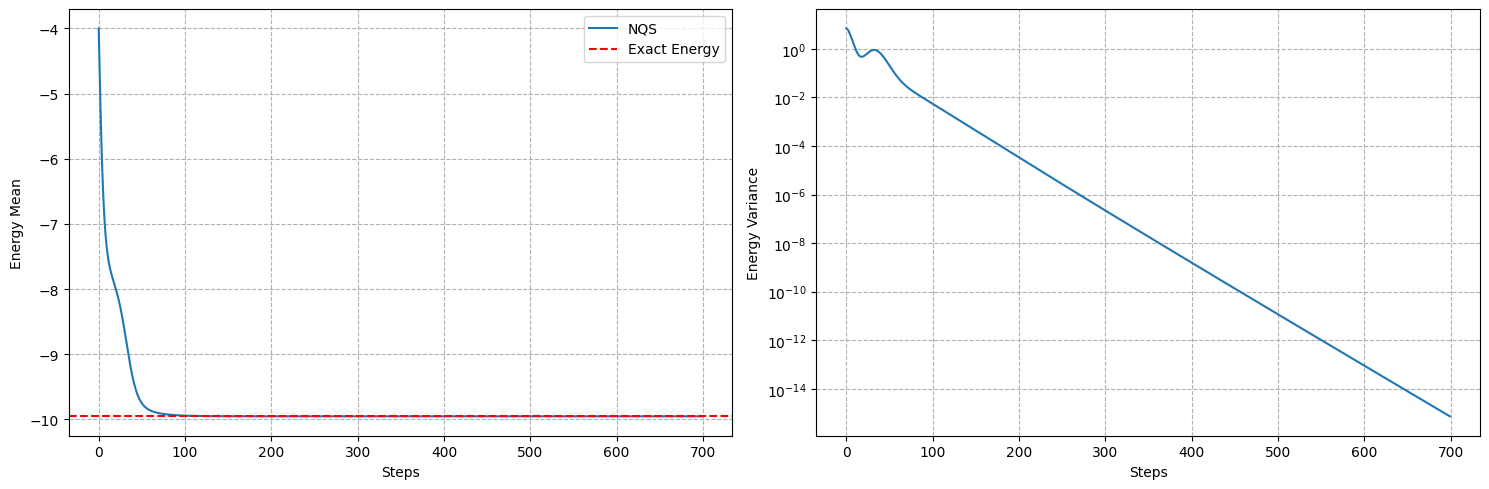

In [17]:
times = out["times"]
energy_mean = np.array(out["energy"]["mean"]).real
energy_var = np.array(out["energy"]["variance"])

plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.plot(times, energy_mean, label="NQS")
plt.axhline(a[0], label="Exact Energy", ls="--", color="red")
plt.ylabel("Energy Mean")
plt.xlabel("Steps")
plt.legend()
plt.grid(ls="--")

plt.subplot(1, 2, 2)
plt.plot(times, energy_var)
plt.yscale("log")
plt.ylabel("Energy Variance")
plt.xlabel("Steps")
plt.grid(ls="--")

plt.tight_layout()

Finally, we compare the optimized wave function with the exact ground state from openfermion, basis state by basis state. `sampler.logPsi` contains $\ln\psi(s)$ for all the configurations `sampler.samples` of the `ExactSampler`.

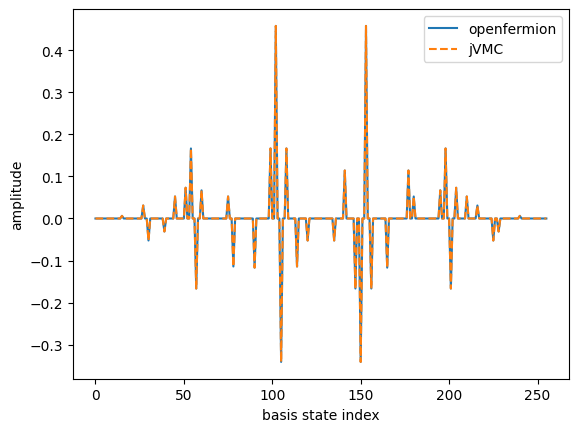

In [19]:
var_wf = np.real(np.exp(sampler.logPsi))
# normalizing the wave function
var_wf /= var_wf.dot(var_wf)**0.5

plt.plot(np.exp(chi(sampler.samples)).real, label='openfermion', zorder=1)
plt.plot(var_wf, label='jVMC', ls="--", zorder=2)
plt.xlabel('basis state index')
plt.ylabel('amplitude')
plt.legend();